#  Recall by PUGS size across seeds

**Description**

Computes recall per PUGS size group for every seed run, then reports the **mean ± STD across seeds** for both models:

- `v0`: Sentinel-2 only
- `v1`: Sentinel-2 + OSM PUGS binary mask

Two recall definitions (same methods as `8_result_analysis.ipynb`):
- Pixel level (sections 4–6): $\text{Recall (\%)} = \frac{\text{Overlap area between GT and pred}}{\text{Total area of Ground truth}} \times 100$
- Per instance (section 7): $\text{Recall (\%)} = \frac{\text{GT polygons detected (coverage} \geq \text{COV\_THR)}}{\text{Total GT polygons}} \times 100$

**Input**
- `dresden_pugs_gt_undissolved.geojson`
- `clipped_dresden_pugs_gt.geotiff`
- `../s{seed}/results/clipped_prediction/clipped_pred_v{0,1}.geotiff` for each seed

**Output** (in `../aggregated_results/`)
- `recall_by_size_all_seeds.csv`, `recall_by_size_summary.csv`, `recall_by_size_mean_std.png`
- `instance_recall_by_size_all_seeds.csv`, `instance_recall_by_size_summary.csv`, `instance_recall_by_size_mean_std.png`

### 1. Import libraries and load config

In [1]:
import os
import sys

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(root_dir)

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml
from rasterstats import zonal_stats
from pugs_detection.ground_truth import merge_overlapping_polygons

In [2]:
with open("../config.yaml", "r") as f:
    config = yaml.safe_load(f)

### 2. Set variables

In [3]:
SEEDS = [1, 7, 10, 11, 42, 50, 51, 100, 101, 150]

# version -> label used in the plot
MODELS = {
    1: "Sentinel-2+OSM PUGS binary mask",
    0: "Sentinel-2 Only",
}

labels = ["<= 0.4", "(0.4, 3]", "(3, 10]", "(10, 80]", "> 80"]

output_dir = "../aggregated_results"
os.makedirs(output_dir, exist_ok=True)

### 3. Ground truth grouped by PUGS size

In [4]:
# Merge overlapping GT polygons (needed for per-instance recall) and group them by size
gt_gdf = gpd.read_file(config["paths"]["gt_undissolved_path"])
merged_gdf = merge_overlapping_polygons(gt_gdf, threshold=0.5)
merged_gdf["area_m2"] = merged_gdf.geometry.area
bins = [0, 4000, 30000, 100000, 800000, merged_gdf["area_m2"].max()]
merged_gdf["area_group"] = pd.cut(merged_gdf["area_m2"], bins=bins, labels=labels, include_lowest=True)

# Dissolve by size group (needed for pixel-level recall)
dissolved_by_group = merged_gdf.dissolve(by="area_group", as_index=False)

# Keep the size-category order
dissolved_by_group["area_group"] = pd.Categorical(dissolved_by_group["area_group"], categories=labels, ordered=True)
dissolved_by_group = dissolved_by_group.sort_values("area_group").reset_index(drop=True)
print(merged_gdf["area_group"].value_counts().sort_index())
dissolved_by_group[["area_group", "geometry"]]

area_group
<= 0.4       531
(0.4, 3]    1018
(3, 10]      150
(10, 80]      88
> 80           8
Name: count, dtype: int64


,area_group,geometry
0,<= 0.4,"MULTIPOLYGON (((404372.437 5654271.712, 404330..."
1,"(0.4, 3]","MULTIPOLYGON (((406684.976 5653066.565, 406679..."
2,"(3, 10]","MULTIPOLYGON (((408615.63 5651144.08, 408616.5..."
3,"(10, 80]","MULTIPOLYGON (((409108.743 5651217.754, 409073..."
4,> 80,"MULTIPOLYGON (((427468.233 5656415.658, 427443..."


In [5]:
# GT pixel count per size group (independent of seed)
stats_gt = zonal_stats(
    dissolved_by_group,  # vector
    config["paths"]["clipped_gt_raster_path"],  # raster
    stats=["sum", "count"],
    nodata=-9999,
)
stats_gt_df = pd.concat([dissolved_by_group[["area_group"]], pd.DataFrame(stats_gt)], axis=1)
stats_gt_df

,area_group,count,sum
0,<= 0.4,9600,9600.0
1,"(0.4, 3]",112338,112338.0
2,"(3, 10]",79500,79500.0
3,"(10, 80]",212904,212904.0
4,> 80,510409,510409.0


### 4. Recall per size group for every seed and model

In [6]:
records = []
for seed in SEEDS:
    for version, model_name in MODELS.items():
        pred_path = config["paths"]["pred_raster_path"].format(seed=seed, version=version)
        if not os.path.exists(pred_path):
            print(f"Missing, skipped: {pred_path}")
            continue

        stats_pred = zonal_stats(
            dissolved_by_group,  # vector
            pred_path,  # raster
            stats=["sum", "count"],
            nodata=-9999,
        )
        pred_sum = pd.DataFrame(stats_pred)["sum"].values

        for area_group, gt_sum, p_sum in zip(stats_gt_df["area_group"], stats_gt_df["sum"], pred_sum):
            records.append({
                "seed": seed,
                "version": version,
                "Input Set": model_name,
                "area_group": area_group,
                "gt_pixels": gt_sum,
                "pred_pixels_in_gt": p_sum,
                "recall": p_sum / gt_sum * 100,
            })

recall_all = pd.DataFrame(records)
recall_all["area_group"] = pd.Categorical(recall_all["area_group"], categories=labels, ordered=True)
recall_all.to_csv(os.path.join(output_dir, "recall_by_size_all_seeds.csv"), index=False)
recall_all.pivot_table(index=["Input Set", "seed"], columns="area_group", values="recall", observed=True).round(2)

area_group                            <= 0.4  (0.4, 3]  (3, 10]  (10, 80]  \
Input Set                       seed                                        
Sentinel-2 Only                 1      24.62     61.41    84.09     93.85   
                                7      25.22     62.42    86.05     94.06   
                                10     35.44     74.78    94.37     97.89   
                                11     23.41     59.67    82.87     92.49   
                                42     25.52     60.33    85.47     93.43   
                                50     25.98     62.17    85.20     93.49   
                                51     23.21     58.97    84.05     93.28   
                                100    23.70     60.50    83.06     93.24   
                                101    25.65     61.25    84.25     93.49   
                                150    25.04     60.97    84.25     93.28   
Sentinel-2+OSM PUGS binary mask 1      30.84     59.86    85.79     94.70   
                                7      31.28     61.09    86.14     94.97   
                                10     34.62     65.26    87.24     95.43   
                                11     30.95     60.01    85.43     94.47   
                                42     30.90     62.17    86.14     95.60   
                                50     29.72     59.39    85.06     94.60   
                                51     32.53     62.31    85.70     95.23   
                                100    31.29     61.63    85.72     94.77   
                                101    34.25     65.57    88.36     95.83   
                                150    30.12     60.75    84.86     94.91   

area_group                             > 80  
Input Set                       seed         
Sentinel-2 Only                 1     99.31  
                                7     99.34  
                                10    99.94  
                                11    99.17  
                                42    99.40  
                                50    99.17  
                                51    99.36  
                                100   99.16  
                                101   99.38  
                                150   99.32  
Sentinel-2+OSM PUGS binary mask 1     99.09  
                                7     99.04  
                                10    99.07  
                                11    98.98  
                                42    99.10  
                                50    99.00  
                                51    98.99  
                                100   98.88  
                                101   99.38  
                                150   99.23

### 5. Mean and STD across seeds

In [7]:
summary = (
    recall_all.groupby(["Input Set", "area_group"], observed=True)["recall"]
    .agg(mean="mean", std="std", n_seeds="count")
    .reset_index()
)
summary.to_csv(os.path.join(output_dir, "recall_by_size_summary.csv"), index=False)

summary_wide = summary.pivot(index="area_group", columns="Input Set", values=["mean", "std"]).round(2)
summary_wide

mean                                             std  \
Input Set  Sentinel-2 Only Sentinel-2+OSM PUGS binary mask Sentinel-2 Only   
area_group                                                                   
<= 0.4               25.78                           31.65            3.53   
(0.4, 3]             62.25                           61.80            4.53   
(3, 10]              85.37                           86.05            3.32   
(10, 80]             93.85                           95.05            1.48   
> 80                 99.36                           99.08            0.22   

                                            
Input Set  Sentinel-2+OSM PUGS binary mask  
area_group                                  
<= 0.4                                1.65  
(0.4, 3]                              2.14  
(3, 10]                               1.05  
(10, 80]                              0.45  
> 80                                  0.14

### 6. Plot mean recall ± STD

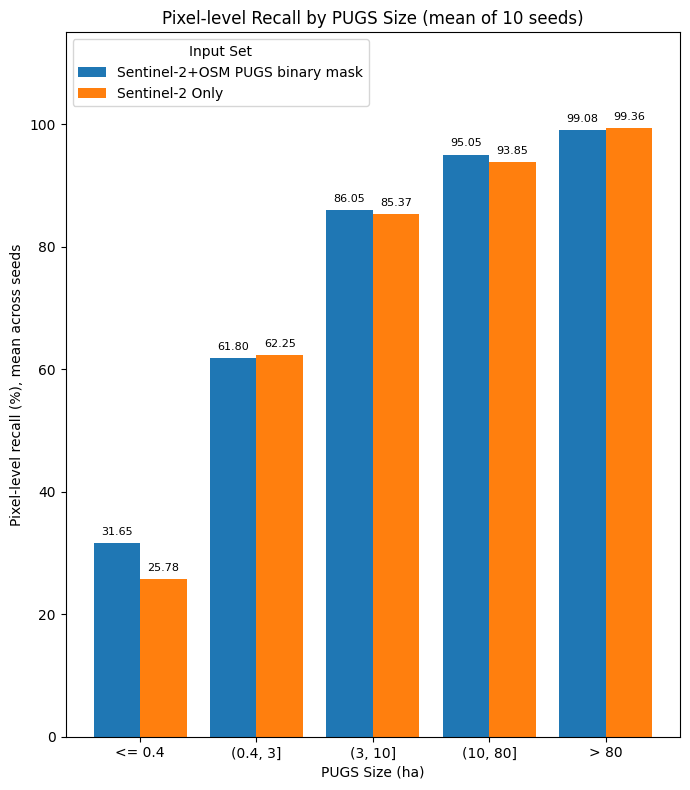

Saved to ../aggregated_results\recall_by_size_mean_std.png


In [16]:
model_names = list(MODELS.values())
colors = ["#1f77b4", "#ff7f0e"]  # same as seaborn default used in 8_result_analysis


def plot_mean_std(summary, title, graph_path, ylabel="Mean recall (%)"):
    """Bars = mean recall across seeds per size group (error bars hidden to declutter)."""
    x = np.arange(len(labels))
    width = 0.4

    fig, ax = plt.subplots(figsize=(7, 8))
    for i, (model_name, color) in enumerate(zip(model_names, colors)):
        s = summary[summary["Input Set"] == model_name].set_index("area_group").reindex(labels)
        pos = x + (i - 0.5) * width
        ax.bar(pos, s["mean"], width,  capsize=4, color=color,   #yerr=s["std"],
               label=model_name, error_kw={"elinewidth": 1, "ecolor": "black"})
        for xi, m in zip(pos, s["mean"]):
            # no error bar drawn, so place the label right above the bar
            ax.text(xi, m + 1, f"{m:.2f}", ha="center", va="bottom", fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel("PUGS Size (ha)")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 115)
    ax.set_title(title)
    ax.legend(title="Input Set", loc="upper left")
    plt.tight_layout()

    plt.savefig(graph_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved to {graph_path}")


plot_mean_std(
    summary,
    f"Pixel-level Recall by PUGS Size (mean of {len(SEEDS)} seeds)",
    os.path.join(output_dir, "recall_by_size_mean_std.png"),
    ylabel="Pixel-level recall (%), mean across seeds",
)

### 7. Per-instance recall per size group for every seed and model

A GT polygon counts as detected when at least `COV_THR` of its pixels are predicted as PUGS (same method as `8_result_analysis.ipynb`, section 4.2/4.4).

$$\text{Recall (\%)} = \frac{\text{GT polygons detected}}{\text{Total GT polygons}} \times 100$$

In [9]:
COV_THR = 0.5

instance_records = []
for seed in SEEDS:
    for version, model_name in MODELS.items():
        pred_path = config["paths"]["pred_raster_path"].format(seed=seed, version=version)
        if not os.path.exists(pred_path):
            print(f"Missing, skipped: {pred_path}")
            continue

        # mean of the binary prediction = fraction of each GT polygon predicted as PUGS
        stats_in_gt = zonal_stats(
            merged_gdf,  # vector
            pred_path,  # raster
            stats=["mean", "count"],
            nodata=-9999,
        )
        stats_in_gt_df = pd.concat(
            [merged_gdf[["area_group", "area_m2"]], pd.DataFrame(stats_in_gt)], axis=1
        )
        stats_in_gt_df["detected"] = stats_in_gt_df["mean"].fillna(0) >= COV_THR

        per_class_detection = (
            stats_in_gt_df.groupby("area_group", observed=True)["detected"]
            .agg(n="size", n_detected="sum", recall="mean")
            .reset_index()
        )
        overall = pd.DataFrame({
            "area_group": ["Overall"],
            "n": [len(stats_in_gt_df)],
            "n_detected": [stats_in_gt_df["detected"].sum()],
            "recall": [stats_in_gt_df["detected"].mean()],
        })
        per_class_detection = pd.concat([per_class_detection, overall], ignore_index=True)
        per_class_detection["recall"] *= 100
        per_class_detection["seed"] = seed
        per_class_detection["version"] = version
        per_class_detection["Input Set"] = model_name
        instance_records.append(per_class_detection)

instance_recall_all = pd.concat(instance_records, ignore_index=True)
instance_recall_all["area_group"] = pd.Categorical(
    instance_recall_all["area_group"], categories=labels + ["Overall"], ordered=True
)
instance_recall_all.to_csv(os.path.join(output_dir, "instance_recall_by_size_all_seeds.csv"), index=False)
instance_recall_all.pivot_table(index=["Input Set", "seed"], columns="area_group", values="recall", observed=True).round(2)

area_group                            <= 0.4  (0.4, 3]  (3, 10]  (10, 80]  \
Input Set                       seed                                        
Sentinel-2 Only                 1      19.59     60.81    90.00     97.73   
                                7      20.34     61.30    90.67     96.59   
                                10     27.87     71.32    95.33     97.73   
                                11     17.70     59.14    88.00     95.45   
                                42     20.53     59.04    91.33     96.59   
                                50     20.53     61.59    92.67     96.59   
                                51     17.33     57.66    90.00     96.59   
                                100    18.46     60.61    89.33     96.59   
                                101    19.59     61.10    90.00     96.59   
                                150    19.96     61.10    89.33     96.59   
Sentinel-2+OSM PUGS binary mask 1      25.42     59.72    92.00     97.73   
                                7      24.86     60.71    92.67     97.73   
                                10     28.81     66.90    91.33     98.86   
                                11     25.05     60.51    92.00     97.73   
                                42     25.05     60.90    91.33     98.86   
                                50     23.92     58.15    91.33     97.73   
                                51     25.99     61.30    91.33     98.86   
                                100    25.05     61.59    93.33     97.73   
                                101    27.12     66.80    94.00     97.73   
                                150    24.11     60.41    92.00     97.73   

area_group                             > 80  Overall  
Input Set                       seed                  
Sentinel-2 Only                 1     100.0    53.04  
                                7     100.0    53.54  
                                10    100.0    61.89  
                                11    100.0    51.25  
                                42    100.0    52.37  
                                50    100.0    53.93  
                                51    100.0    50.53  
                                100   100.0    52.48  
                                101   100.0    53.15  
                                150   100.0    53.20  
Sentinel-2+OSM PUGS binary mask 1     100.0    54.32  
                                7     100.0    54.76  
                                10    100.0    59.39  
                                11    100.0    54.65  
                                42    100.0    54.87  
                                50    100.0    52.92  
                                51    100.0    55.38  
                                100   100.0    55.38  
                                101   100.0    59.00  
                                150   100.0    54.32

In [10]:
instance_summary = (
    instance_recall_all.groupby(["Input Set", "area_group"], observed=True)
    .agg(n=("n", "first"), mean=("recall", "mean"), std=("recall", "std"), n_seeds=("recall", "count"))
    .reset_index()
)
instance_summary.to_csv(os.path.join(output_dir, "instance_recall_by_size_summary.csv"), index=False)

instance_summary.pivot(index="area_group", columns="Input Set", values=["mean", "std"]).round(2)

mean                                             std  \
Input Set  Sentinel-2 Only Sentinel-2+OSM PUGS binary mask Sentinel-2 Only   
area_group                                                                   
<= 0.4               20.19                           25.54            2.93   
(0.4, 3]             61.37                           61.70            3.71   
(3, 10]              90.67                           92.13            2.06   
(10, 80]             96.70                           98.07            0.65   
> 80                100.00                          100.00            0.00   
Overall              53.54                           55.50            3.11   

                                            
Input Set  Sentinel-2+OSM PUGS binary mask  
area_group                                  
<= 0.4                                1.46  
(0.4, 3]                              2.87  
(3, 10]                               0.93  
(10, 80]                              0.55  
> 80                                  0.00  
Overall                               2.07

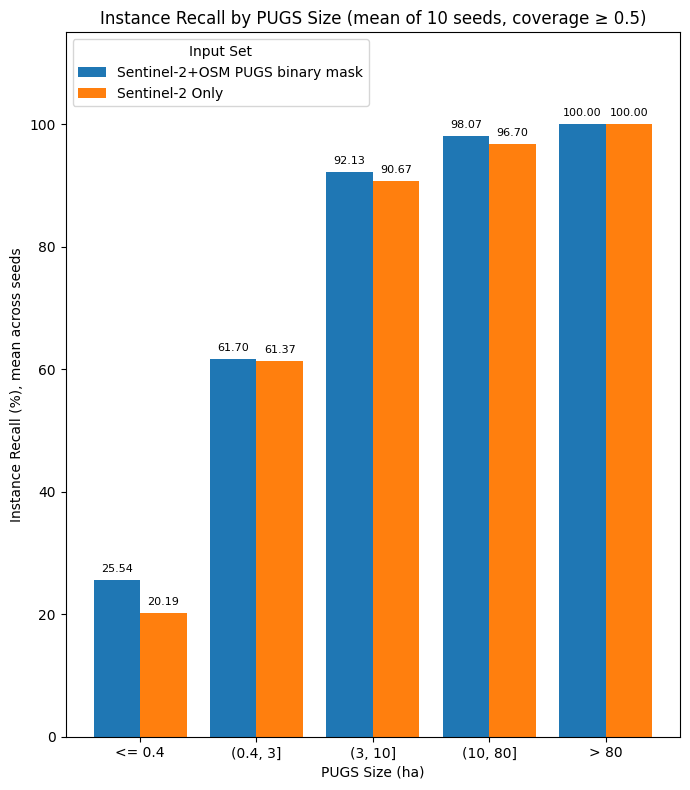

Saved to ../aggregated_results\instance_recall_by_size_mean_std.png


In [17]:
plot_mean_std(
    instance_summary[instance_summary["area_group"] != "Overall"],
    f"Instance Recall by PUGS Size (mean of {len(SEEDS)} seeds, coverage ≥ {COV_THR})",
    os.path.join(output_dir, "instance_recall_by_size_mean_std.png"),
    ylabel="Instance Recall (%), mean across seeds",
)

### 8. Gain in per-instance recall from adding OSM (v1 − v0)

The gain is computed per seed (paired: both models trained with the same seed), then summarised across seeds.

- Absolute gain (percentage points): $\text{recall}_{v1} - \text{recall}_{v0}$
- Relative gain (%): $\frac{\text{recall}_{v1} - \text{recall}_{v0}}{\text{recall}_{v0}} \times 100$
- Extra detected: number of additional GT polygons detected by v1

In [12]:
# Pair v0 and v1 by seed and size group
paired = (
    instance_recall_all[instance_recall_all["version"] == 0][["seed", "area_group", "n", "n_detected", "recall"]]
    .merge(
        instance_recall_all[instance_recall_all["version"] == 1][["seed", "area_group", "n_detected", "recall"]],
        on=["seed", "area_group"],
        suffixes=("_no_osm", "_osm"),
    )
)
paired["extra_detected"] = paired["n_detected_osm"] - paired["n_detected_no_osm"]
paired["recall_gain_pp"] = paired["recall_osm"] - paired["recall_no_osm"]
paired["recall_gain_rel_%"] = paired["recall_gain_pp"] / paired["recall_no_osm"] * 100

paired.to_csv(os.path.join(output_dir, "instance_recall_gain_all_seeds.csv"), index=False)
paired.pivot_table(index="seed", columns="area_group", values="recall_gain_pp", observed=True).round(2)

area_group,<= 0.4,"(0.4, 3]","(3, 10]","(10, 80]",> 80,Overall
seed,,,,,,
1,5.84,-1.08,2.00,0.00,0.0,1.28
7,4.52,-0.59,2.00,1.14,0.0,1.23
10,0.94,-4.42,-4.00,1.14,0.0,-2.51
11,7.34,1.38,4.00,2.27,0.0,3.40
42,4.52,1.87,0.00,2.27,0.0,2.51
50,3.39,-3.44,-1.33,1.14,0.0,-1.00
51,8.66,3.63,1.33,2.27,0.0,4.85
100,6.59,0.98,4.00,1.14,0.0,2.90
101,7.53,5.70,4.00,1.14,0.0,5.85


In [20]:
gain_summary = (
    paired.groupby("area_group", observed=True)
    .agg(
        n=("n", "first"),
        detected_no_osm_mean=("n_detected_no_osm", "mean"),
        # detected_no_osm_std=("n_detected_no_osm", "std"),
        detected_osm_mean=("n_detected_osm", "mean"),
        # detected_osm_std=("n_detected_osm", "std"),
        extra_detected_mean=("extra_detected", "mean"),
        recall_no_osm_mean=("recall_no_osm", "mean"),
        recall_osm_mean=("recall_osm", "mean"),
        gain_pp_mean=("recall_gain_pp", "mean"),
        # gain_pp_std=("recall_gain_pp", "std"),
        # gain_pp_median=("recall_gain_pp", "median"),
        gain_rel_mean=("recall_gain_rel_%", "mean"),
        # gain_rel_std=("recall_gain_rel_%", "std"),
        # gain_rel_median=("recall_gain_rel_%", "median"),
        seeds_with_gain=("recall_gain_pp", lambda g: int((g > 0).sum())),
        n_seeds=("recall_gain_pp", "count"),
    )
    .reset_index()
)
gain_summary.to_csv(os.path.join(output_dir, "instance_recall_gain_summary_v2.csv"), index=False)
gain_summary.round(2)

,area_group,n,detected_no_osm_mean,detected_osm_mean,extra_detected_mean,recall_no_osm_mean,recall_osm_mean,gain_pp_mean,gain_rel_mean,seeds_with_gain,n_seeds
0,<= 0.4,531,107.2,135.6,28.4,20.19,25.54,5.35,28.04,10,10
1,"(0.4, 3]",1018,624.7,628.1,3.4,61.37,61.70,0.33,0.71,5,10
2,"(3, 10]",150,136.0,138.2,2.2,90.67,92.13,1.47,1.67,7,10
3,"(10, 80]",88,85.1,86.3,1.2,96.70,98.07,1.36,1.41,9,10
4,> 80,8,8.0,8.0,0.0,100.00,100.00,0.00,0.00,0,10
5,Overall,1795,961.0,996.2,35.2,53.54,55.50,1.96,3.84,8,10
